In [6]:
# Auto-switch to repo root so relative paths (configs/, scripts/, data/) work
from pathlib import Path
import os

_cwd = Path.cwd()
_root = _cwd
while _root != _root.parent:
    if (_root / "configs" / "config.yaml").exists():
        break
    _root = _root.parent
os.chdir(_root)
print(f"Repo root: {_root}")


Repo root: c:\Users\karki\Downloads\main_openworld\openworld


# 01 — Data exploration and protocol (Phase 0)

Validates the 15 base + 5 novel category protocol, builds fixed train / val-tune / val-test image-ID manifests, and writes slim COCO annotation JSONs. Nothing is trained here.

Before running, copy your two annotation JSONs into `data/annotations/`:
- `instances_train2017.json`
- `instances_val2017.json`


In [14]:
from pathlib import Path
import yaml, json
from pprint import pprint

cfg = yaml.safe_load(open("configs/config.yaml"))
print("Project:", cfg["project"]["name"], "| device:", cfg["project"]["device"])
print()
print("Selected classes:")
pprint(cfg["selected_classes"])


Project: openworld | device: cpu

Selected classes:
{'base': ['person',
          'car',
          'chair',
          'bottle',
          'bicycle',
          'motorcycle',
          'truck',
          'horse',
          'sheep',
          'bench',
          'laptop',
          'tv',
          'book',
          'backpack',
          'bird'],
 'novel': ['bus', 'dog', 'elephant', 'umbrella', 'keyboard']}


In [8]:
%run scripts/prepare_data.py --config configs/config.yaml


loading annotations into memory...
Done (t=11.72s)
creating index...
index created!
loading annotations into memory...
Done (t=0.53s)
creating index...
index created!
===== Phase 0 complete =====
train images : 2000
val tune     : 500
val test     : 1500
categories   : 15 base + 5 novel
co-occurrence base+novel train images: 294
train box sizes: {'small': 3379, 'medium': 3839, 'large': 3489}
train images missing locally: 2000


In [15]:
import json
from pprint import pprint

meta = json.load(open("data/splits/split_metadata.json"))
print("Split metadata:")
pprint(meta)

counts = json.load(open("data/metadata/category_counts.json"))
print()
print("Category counts (train / val-tune / val-test):")
for name, c in counts.items():
    print(f"  {name:12s} [{c['split']:5s}] train={c['train_instances']:5d} imgs, "
          f"tune={c['val_tune_instances']:4d} imgs, test={c['val_test_instances']:4d} imgs")


Split metadata:
{'base_classes': ['person',
                  'car',
                  'chair',
                  'bottle',
                  'bicycle',
                  'motorcycle',
                  'truck',
                  'horse',
                  'sheep',
                  'bench',
                  'laptop',
                  'tv',
                  'book',
                  'backpack',
                  'bird'],
 'note': 'Base-only supervision: train images keep base annotations only; '
         'novel annotations in those images are dropped as supervision.',
 'novel_classes': ['bus', 'dog', 'elephant', 'umbrella', 'keyboard'],
 'num_train_images': 2000,
 'num_val_test_images': 1500,
 'num_val_tune_images': 500,
 'seed': 42,
 'val_tune_fraction': 0.25}

Category counts (train / val-tune / val-test):
  person       [base ] train= 5643 imgs, tune=1408 imgs, test=4243 imgs
  car          [base ] train= 1051 imgs, tune= 258 imgs, test= 846 imgs
  chair        [base ] train=  98

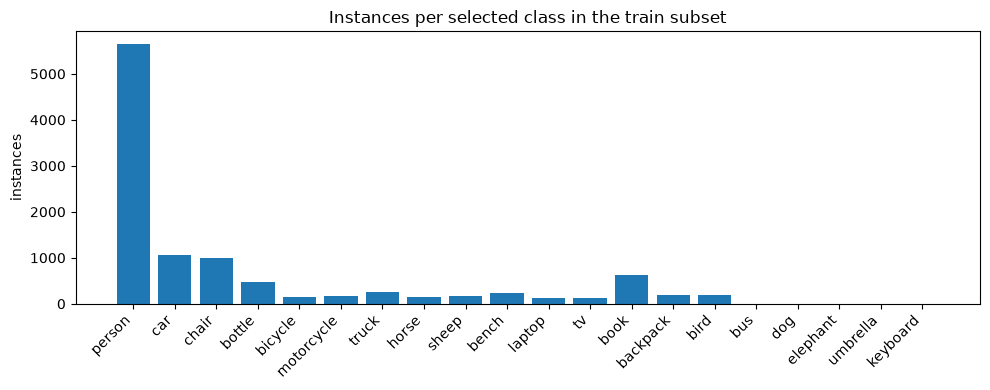

In [10]:
import json
import matplotlib.pyplot as plt

counts = json.load(open("data/metadata/category_counts.json"))
names = list(counts.keys())
train_vals = [counts[n]["train_instances"] for n in names]

plt.figure(figsize=(10, 4))
plt.bar(names, train_vals)
plt.xticks(rotation=45, ha="right")
plt.ylabel("instances")
plt.title("Instances per selected class in the train subset")
plt.tight_layout()
plt.show()


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!


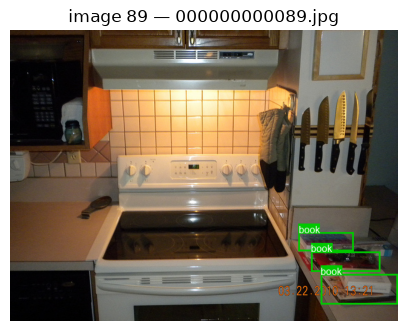

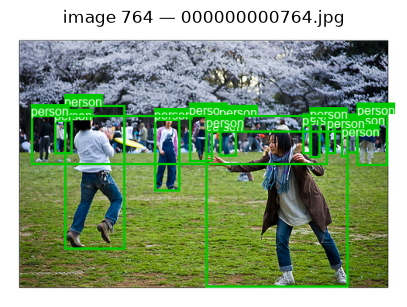

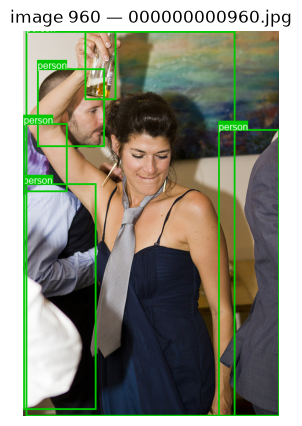

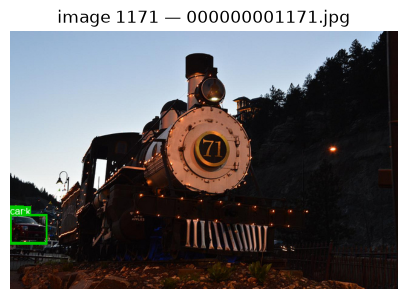

In [16]:
from pycocotools.coco import COCO
from PIL import Image
import matplotlib.pyplot as plt
from src.openworld.visualization import draw_boxes

coco = COCO("data/annotations/instances_train2017.stripped.json")
train_ids = json.load(open("data/splits/train_image_ids.json"))

for iid in train_ids[:4]:
    img = coco.loadImgs(iid)[0]
    ann_ids = coco.getAnnIds(imgIds=iid)
    anns = coco.loadAnns(ann_ids)
    image = Image.open("data/images/train2017/" + img["file_name"]).convert("RGB")
    boxes = [[a["bbox"][0], a["bbox"][1], a["bbox"][0] + a["bbox"][2],
              a["bbox"][1] + a["bbox"][3]] for a in anns]
    labels = [coco.cats[a["category_id"]]["name"] for a in anns]
    plt.figure(figsize=(5, 5))
    plt.imshow(draw_boxes(image, boxes, labels))
    plt.axis("off")
    plt.title(f"image {iid} — {img['file_name']}")
    plt.show()
